# Figure 3

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_loo_comparison,
    load_robustness_loo,
    load_ddm_subj_params,
    load_choicehistorypersubject_betas,
    load_rtlme_switchpersubject_betas,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pingouin as pg
import statsmodels.api as sm

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
FULL_DDM_MODEL = "HDDM_Base_Lag1-stpdrift"

### Helper functions

In [2]:
BF_THRESHOLD_HIGH = 3
BF_THRESHOLD_LOW = 1 / 3

BF_COLORS = {
    "evidence_for":     "#017D01",
    "inconclusive":     "#B0B0B0",
    "evidence_against": "#6A51A3",
}


def bf_category(bf10):
    if bf10 > BF_THRESHOLD_HIGH:
        return "evidence_for"
    if bf10 < BF_THRESHOLD_LOW:
        return "evidence_against"
    return "inconclusive"

def pearson_corr_bf(x, y):
    """Pearson r/p plus the JZS Bayes Factor (BF10), and an OLS line + 95%
    CI band fit on every point."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    res = pg.corr(x, y, method="pearson")
    r = float(res["r"].iloc[0])
    pval = float(res["p_val"].iloc[0])
    bf10 = float(res["BF10"].iloc[0])
    category = bf_category(bf10)

    ols_fit = sm.OLS(y, sm.add_constant(x)).fit()
    x_line = np.linspace(x.min(), x.max(), 100)
    pred = ols_fit.get_prediction(sm.add_constant(x_line)).summary_frame(alpha=0.05)

    return {
        "r": r,
        "pval": pval,
        "bf10": bf10,
        "category": category,
        "n": len(x),
        "x_line": x_line,
        "y_line": pred["mean"].values,
        "ci_low": pred["mean_ci_lower"].values,
        "ci_high": pred["mean_ci_upper"].values,
    }


def style_axis(ax, col=None, ylabel=None, xlabel=None, xlabel_col=1):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0 and ylabel:
        ax.set_ylabel(ylabel)
    if col == xlabel_col and xlabel:
        ax.set_xlabel(xlabel)

def format_bf(bf10):
    # one decimal point
    return f"{np.log10(bf10):.1f}"


def format_pval(p):
    if p < 0.001:
        return "<.001"
    if p < 0.01:
        return "<.01"
    if p < 0.05:
        return "<.05"
    return "=n.s."


def plot_pearson_corr(ax, x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    result = pearson_corr_bf(x, y)
    color = BF_COLORS[result["category"]]

    ax.scatter(x, y, color=color, alpha=0.75, edgecolor="black",
               linewidth=0.5, s=75, zorder=3)
    ax.fill_between(result["x_line"], result["ci_low"], result["ci_high"],
                     color=color, alpha=0.15, zorder=1)
    ax.plot(result["x_line"], result["y_line"], color=color, linewidth=1.5,
            linestyle="--", zorder=4)

    ax.text(0.05, 0.95,
            f"r = {result['r']:.2f}, p {format_pval(result['pval'])}\n"
            f"log10(BF10) = {format_bf(result['bf10'])}\nn = {result['n']}",
            transform=ax.transAxes, ha="left", va="top", fontsize = 14,
            color=color, fontweight="bold")


    return result


def compute_elpd_vs_baseline(dataset, baseline_model, model_order):
    loo = (load_loo_comparison(dataset, group_name = "choicehistory")
           .set_index("model")["elpd_loo"])
    baseline_elpd = loo[baseline_model]
    return [loo[m] - baseline_elpd for m, _ in model_order]


def compute_elpd_robustness_vs_baseline(dataset, baseline_model, model_order,
                                        column="elpd_loo_reliable_only"):
    loo = load_robustness_loo(dataset, group_name = "choicehistory").set_index("model")[column]

    diffs = []
    for model_id, _ in model_order:
        diffs.append(loo[model_id] - loo[baseline_model])
    return diffs


def elpd_vs_robustness_table(dataset, group_name):
    """elpd_loo (real) vs elpd_loo_reliable_only (robustness) for every
    model in one LOO comparison group."""
    real = load_loo_comparison(dataset, group_name=group_name).set_index("model")["elpd_loo"]
    robust = load_robustness_loo(dataset, group_name=group_name).set_index("model")["elpd_loo_reliable_only"]
    return pd.DataFrame({"elpd_loo": real, "elpd_loo_reliable_only": robust}).reset_index()


ELPD_THRESHOLD = 4

ELPD_COLORS = {
    "improved":  "#017D01",
    "ambiguous": "#8D8D8D",
    "worse":     "#980B0B",
}
ELPD_LABELS = {
    "improved":  "∆elpd > 4",
    "ambiguous": "otherwise",
    "worse":     "∆elpd < -4",
}


def elpd_category(diff):
    if diff > ELPD_THRESHOLD:
        return "improved"
    if diff < -ELPD_THRESHOLD:
        return "worse"
    return "ambiguous"


def plot_elpd_bars(ax, diffs, x_labels, col, show_legend=False):
    x_pos = np.arange(len(diffs))
    colors = [ELPD_COLORS[elpd_category(d)] for d in diffs]
    ax.bar(x_pos, diffs, color=colors, width=0.6, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(-8, 200)
    style_axis(ax, col, ylabel="Improvement over \nbaseline DDM (∆elpd-loo)",
              xlabel="DDM parameter(s) shifted by choice history")

    if show_legend:
        handles = [mpatches.Patch(facecolor=ELPD_COLORS[cat], label=ELPD_LABELS[cat])
                  for cat in ("improved", "worse", "ambiguous")]
        ax.legend(handles=handles, loc="upper left")

### 3x3 figure:
1. LOO improvement
2. Correlation scatterplot
3. Correlation scatterplot


choicehistory_betas
dataset
equalIndifference    45
equalRange           46
sheng2020            62

switch_betas
dataset
equalIndifference    54
equalRange           54
sheng2020            82

Fixed drift rate (v_choice_prev1) vs. switch effect on RT:
  equalIndifference: r = 0.40, p = 0.00242, log10(BF10) = 1.2, n = 54
  equalRange: r = 0.12, p = 0.45, log10(BF10) = -0.6, n = 39
  sheng2020: r = 0.39, p = 0.000302, log10(BF10) = 1.9, n = 82

Starting point (z_choice_prev1) vs. gamble acceptance probability effect:
  equalIndifference: r = 0.14, p = 0.347, log10(BF10) = -0.5, n = 45
  equalRange: r = 0.00, p = 0.999, log10(BF10) = -0.7, n = 45
  sheng2020: r = 0.46, p = 0.000155, log10(BF10) = 2.2, n = 62


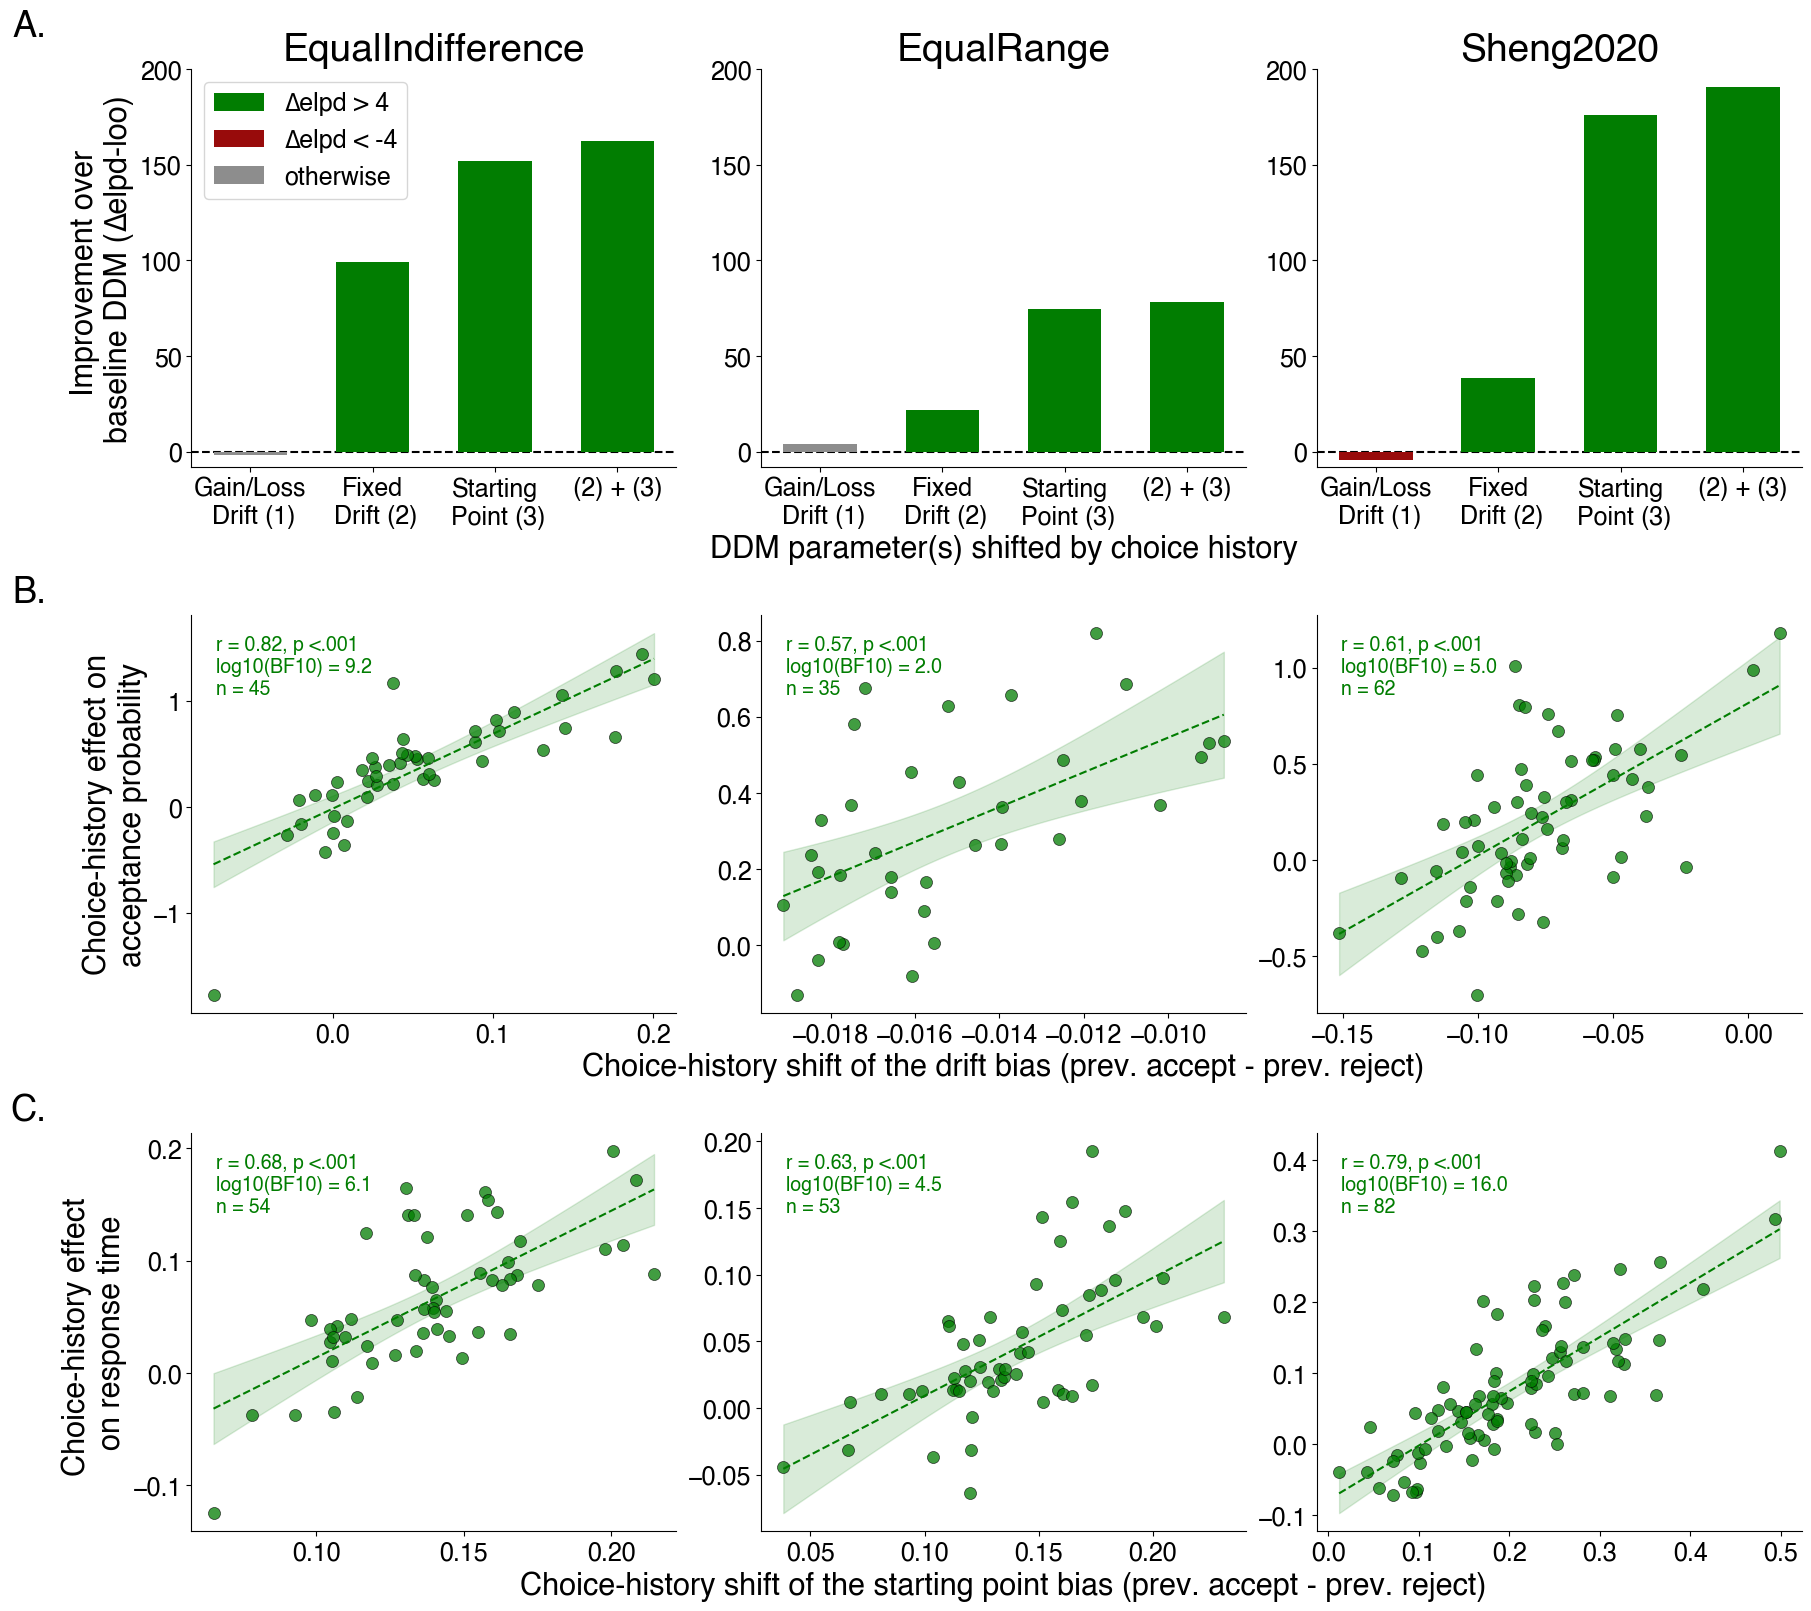

In [3]:
BASELINE_MODEL = "HDDM_Base"

ELPD_MODEL_ORDER = [
    ("HDDM_Base_Lag1-stim",  "Gain/Loss\n Drift (1)"),
    ("HDDM_Base_Lag1-drift", "Fixed\n Drift (2)"),
    ("HDDM_Base_Lag1-stp",   "Starting\n Point (3)"),
    ("HDDM_Base_Lag1-stpdrift",  "(2) + (3)"),
]

manual_exclusions_drift = {
    "equalIndifference": [],
    "equalRange": [4, 6, 10, 20, 22, 32, 38, 50, 52, 56, 96, 106, 112, 116, 124],
    "sheng2020": []
}

manual_exclusions_stp = {
    "equalIndifference": [],
    "equalRange": [58],
    "sheng2020": []
}

choicehistory_betas = load_choicehistorypersubject_betas()
choicehistory_betas = choicehistory_betas[choicehistory_betas["converged"]]
switch_betas = load_rtlme_switchpersubject_betas()
switch_betas = switch_betas[switch_betas["converged"]]

for name, betas_df in [("choicehistory_betas", choicehistory_betas), ("switch_betas", switch_betas)]:
    print(f"\n{name}")
    print(betas_df.groupby("dataset")["sub"].nunique().to_string())

elpd_vs_baseline = {}
drift_vs_choice = {}
z_vs_switch = {}
drift_vs_switch = {}
z_vs_choice = {}

for ds in DATASETS:
    elpd_vs_baseline[ds] = compute_elpd_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER)

    full_params = (load_ddm_subj_params(FULL_DDM_MODEL, ds)
                   .pivot(index="sub", columns="param_name", values="param_value"))

    beh_ds = (choicehistory_betas[choicehistory_betas["dataset"] == ds]
              .set_index("sub")["choice_prev1_effect"])
    switch_ds = (switch_betas[switch_betas["dataset"] == ds]
                 .set_index("sub")["switch_effect"])

    drift_vs_choice[ds] = pd.concat(
        [full_params["v_choice_prev1"].rename("v_choice_prev1"), beh_ds.rename("choice_prev1_effect")],
        axis=1, join="inner",
    ).drop(index=manual_exclusions_drift[ds], errors="ignore")
    z_vs_switch[ds] = pd.concat(
        [full_params["z_choice_prev1"].rename("z_choice_prev1"), switch_ds.rename("switch_effect")],
        axis=1, join="inner",
    ).drop(index=manual_exclusions_stp[ds], errors="ignore")

    # Cross-pairings (not plotted): fixed drift rate vs. the RT switch
    # effect, and the starting point vs. gamble acceptance probability.
    drift_vs_switch[ds] = pd.concat(
        [full_params["v_choice_prev1"].rename("v_choice_prev1"), switch_ds.rename("switch_effect")],
        axis=1, join="inner",
    ).drop(index=manual_exclusions_drift[ds], errors="ignore")
    z_vs_choice[ds] = pd.concat(
        [full_params["z_choice_prev1"].rename("z_choice_prev1"), beh_ds.rename("choice_prev1_effect")],
        axis=1, join="inner",
    ).drop(index=manual_exclusions_stp[ds], errors="ignore")

print("\nFixed drift rate (v_choice_prev1) vs. switch effect on RT:")
for ds in DATASETS:
    merged = drift_vs_switch[ds]
    result = pearson_corr_bf(merged["v_choice_prev1"].values, merged["switch_effect"].values)
    print(f"  {ds}: r = {result['r']:.2f}, p = {result['pval']:.3g}, "
         f"log10(BF10) = {format_bf(result['bf10'])}, n = {result['n']}")

print("\nStarting point (z_choice_prev1) vs. gamble acceptance probability effect:")
for ds in DATASETS:
    merged = z_vs_choice[ds]
    result = pearson_corr_bf(merged["z_choice_prev1"].values, merged["choice_prev1_effect"].values)
    print(f"  {ds}: r = {result['r']:.2f}, p = {result['pval']:.3g}, "
         f"log10(BF10) = {format_bf(result['bf10'])}, n = {result['n']}")

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 16), layout="constrained")
elpd_labels = [label for _, label in ELPD_MODEL_ORDER]

for col, ds in enumerate(DATASETS):
    plot_elpd_bars(axes[0, col], elpd_vs_baseline[ds], elpd_labels, col, show_legend=(col == 0))
    axes[0, col].set_title(DATASET_LABELS.get(ds, ds))

    merged = drift_vs_choice[ds]
    plot_pearson_corr(axes[1, col], merged["v_choice_prev1"].values, merged["choice_prev1_effect"].values)
    style_axis(axes[1, col], col,
              ylabel="Choice-history effect on\nacceptance probability",
              xlabel="Choice-history shift of the drift bias (prev. accept - prev. reject)")

    merged = z_vs_switch[ds]
    plot_pearson_corr(axes[2, col], merged["z_choice_prev1"].values, merged["switch_effect"].values)
    style_axis(axes[2, col], col,
              ylabel="Choice-history effect \non response time",
              xlabel="Choice-history shift of the starting point bias (prev. accept - prev. reject)")

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
for row, label in enumerate(["A.", "B.", "C."]):
    y = 1.15 if row == 0 else 1.1
    axes[row, 0].text(-0.3, y, label, transform=axes[row, 0].transAxes,
                      fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure3.svg", dpi=300, bbox_inches="tight")
plt.show()

### Robustness check
Per dataset: ∆elpd (baseline vs. model, from Row A) next to the PSIS-LOO robustness-check ∆elpd (same comparison restricted to observations with reliable Pareto-k, `elpd_loo_reliable_only`).

In [4]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-stim",  "Gain/Loss\n Drift (1)"),
    ("HDDM_Base_Lag1-drift", "Fixed\n Drift (2)"),
    ("HDDM_Base_Lag1-stp",   "Starting\n Point (3)"),
    ("HDDM_Base_Lag1-stpdrift",  "(2) + (3)"),
    ("HDDM_Base_Lag1-full", "(1) + (2) + (3)")
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
                model  delta_elpd  delta_elpd_robust
Gain/Loss\n Drift (1)   -1.476759          -3.184835
    Fixed\n Drift (2)   99.352246          99.547728
 Starting\n Point (3)  151.692313         121.989397
            (2) + (3)  162.354493         136.967219
      (1) + (2) + (3)  158.072678         133.872453

equalRange
                model  delta_elpd  delta_elpd_robust
Gain/Loss\n Drift (1)    3.878474           3.658645
    Fixed\n Drift (2)   21.858156          20.986850
 Starting\n Point (3)   74.481972          57.626295
            (2) + (3)   78.348829          60.807655
      (1) + (2) + (3)   76.716253          58.330030

sheng2020
                model  delta_elpd  delta_elpd_robust
Gain/Loss\n Drift (1)   -4.523189          -3.544539
    Fixed\n Drift (2)   38.324040          41.037460
 Starting\n Point (3)  176.002296         150.134298
            (2) + (3)  190.334745         159.984397
      (1) + (2) + (3)  188.597556         157.659556


In [5]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-stpdrift",  "stpdrift"),
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, "HDDM_Base_Lag1-stp", ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, "HDDM_Base_Lag1-stp", ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
   model  delta_elpd  delta_elpd_robust
stpdrift    10.66218          14.977821

equalRange
   model  delta_elpd  delta_elpd_robust
stpdrift    3.866857            3.18136

sheng2020
   model  delta_elpd  delta_elpd_robust
stpdrift    14.33245           9.850099


In [6]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-full",  "full"),
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, "HDDM_Base_Lag1-stpdrift", ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, "HDDM_Base_Lag1-stpdrift", ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
model  delta_elpd  delta_elpd_robust
 full   -4.281815          -3.094766

equalRange
model  delta_elpd  delta_elpd_robust
 full   -1.632576          -2.477625

sheng2020
model  delta_elpd  delta_elpd_robust
 full    -1.73719          -2.324841


### Individual shift in starting point vs. fixed drift
Per-subject Pearson correlation between the choice-history shift in the starting-point bias (`z_choice_prev1`) and the fixed-drift bias (`v_choice_prev1`), both from the same full model (`HDDM_Base_Lag1-stpdrift`). Subjects manually excluded from either parameter's own convergence check (union of `manual_exclusions_drift`/`manual_exclusions_stp`, defined above) are dropped.

In [7]:
drift_vs_stp = {}

print("Individual shift in fixed drift (v_choice_prev1) vs. starting point (z_choice_prev1):")
for ds in DATASETS:
    full_params = (load_ddm_subj_params(FULL_DDM_MODEL, ds)
                   .pivot(index="sub", columns="param_name", values="param_value"))
    exclude_ds = sorted(set(manual_exclusions_drift[ds]) | set(manual_exclusions_stp[ds]))
    merged = full_params[["v_choice_prev1", "z_choice_prev1"]].drop(index=exclude_ds, errors="ignore")
    drift_vs_stp[ds] = merged

    result = pearson_corr_bf(merged["v_choice_prev1"].values, merged["z_choice_prev1"].values)
    print(f"  {ds}: r = {result['r']:.2f}, p = {result['pval']:.3g}, "
         f"log10(BF10) = {format_bf(result['bf10'])}, n = {result['n']}")

Individual shift in fixed drift (v_choice_prev1) vs. starting point (z_choice_prev1):
  equalIndifference: r = 0.35, p = 0.00865, log10(BF10) = 0.7, n = 54
  equalRange: r = 0.17, p = 0.305, log10(BF10) = -0.5, n = 38
  sheng2020: r = 0.47, p = 7.05e-06, log10(BF10) = 3.4, n = 82
